--------- Predicting Premier League match outcomes to maximize investment in football club sponsorships: a cost-benefit perspective ---------


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df1  = pd.read_csv("season-2526.csv")
df2  = pd.read_csv("season-2425.csv")
df3  = pd.read_csv("season-2324.csv")
df4  = pd.read_csv("season-2223.csv")
df5  = pd.read_csv("season-2122.csv")
df6  = pd.read_csv("season-2021.csv")
df7  = pd.read_csv("season-1920.csv")
df8  = pd.read_csv("season-1819.csv")
df9  = pd.read_csv("season-1718.csv")
df10 = pd.read_csv("season-1617.csv")

df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10], ignore_index=True)

In [33]:
df.head() #First rows and columns to see in the data

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0


In [32]:
df.describe() # To check relevant datas

,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
count,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000,3800.000000
mean,1.555263,1.279737,0.697895,0.564211,13.867105,11.480263,4.768158,4.023421,10.598158,10.868158,5.664474,4.687632,1.656579,1.850000,0.053947,0.061053
std,1.313304,1.207771,0.847582,0.780172,5.685582,5.060168,2.618839,2.362564,3.426335,3.562880,3.060554,2.796334,1.271598,1.311911,0.236196,0.244893
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,10.000000,8.000000,3.000000,2.000000,8.000000,8.000000,3.000000,3.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,13.000000,11.000000,4.000000,4.000000,10.000000,11.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,1.000000,1.000000,17.000000,15.000000,6.000000,5.000000,13.000000,13.000000,8.000000,6.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,9.000000,5.000000,5.000000,37.000000,37.000000,17.000000,15.000000,24.000000,26.000000,19.000000,19.000000,7.000000,8.000000,2.000000,2.000000


In [31]:
df['HomeTeam'].unique() #Total number of teams that played in the Premier League in the last 10 years

<ArrowStringArray>
[       'Liverpool',      'Aston Villa',         'Brighton',
       'Sunderland',        'Tottenham',           'Wolves',
          'Chelsea',    'Nott'm Forest',       'Man United',
            'Leeds',         'West Ham',         'Man City',
      'Bournemouth',        'Brentford',          'Burnley',
          'Arsenal',   'Crystal Palace',          'Everton',
           'Fulham',        'Newcastle',          'Ipswich',
        'Leicester',      'Southampton', 'Sheffield United',
            'Luton',          'Watford',          'Norwich',
        'West Brom',     'Huddersfield',          'Cardiff',
            'Stoke',          'Swansea',             'Hull',
    'Middlesbrough']
Length: 34, dtype: str

In [30]:
df.shape #Total of rows and columns. (In other words: total number of matches = 3800; 22 columns of different info)

(3800, 22)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      3800 non-null   str  
 1   HomeTeam  3800 non-null   str  
 2   AwayTeam  3800 non-null   str  
 3   FTHG      3800 non-null   int64
 4   FTAG      3800 non-null   int64
 5   FTR       3800 non-null   str  
 6   HTHG      3800 non-null   int64
 7   HTAG      3800 non-null   int64
 8   HTR       3800 non-null   str  
 9   Referee   3800 non-null   str  
 10  HS        3800 non-null   int64
 11  AS        3800 non-null   int64
 12  HST       3800 non-null   int64
 13  AST       3800 non-null   int64
 14  HF        3800 non-null   int64
 15  AF        3800 non-null   int64
 16  HC        3800 non-null   int64
 17  AC        3800 non-null   int64
 18  HY        3800 non-null   int64
 19  AY        3800 non-null   int64
 20  HR        3800 non-null   int64
 21  AR        3800 non-null   int64
dtypes: int64(16

In [28]:
df.isnull().sum() #Check if there are any null values to dropna.

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

In [29]:
df[['Date', 'HomeTeam',	'AwayTeam',	'FTHG',	'FTAG']].head() #Check what columns see

,Date,HomeTeam,AwayTeam,FTHG,FTAG
0,2025-08-15,Liverpool,Bournemouth,4,2
1,2025-08-16,Aston Villa,Newcastle,0,0
2,2025-08-16,Brighton,Fulham,1,1
3,2025-08-16,Sunderland,West Ham,3,0
4,2025-08-16,Tottenham,Burnley,3,0


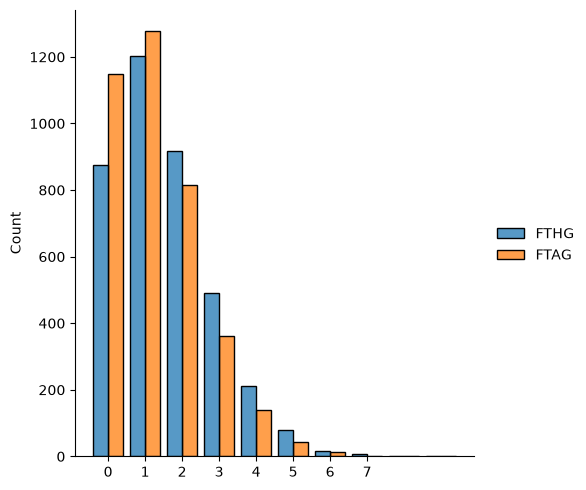

In [6]:
graph = sns.displot(df[['FTHG', 'FTAG']],multiple='dodge', discrete = True, shrink=0.8);graph.set(xticks=range(0,8))
#To check how many goals per match. home goals x away goals